In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load data

In [2]:
data = pd.read_csv("../data/raw/matches-pre2018.csv")
data

,Year,Datetime,Stage,Stadium,City,Home Team Name,Home Team Goals,Away Team Goals,Away Team Name,Win conditions,Attendance,Half-time Home Goals,Half-time Away Goals,Referee,Assistant 1,Assistant 2,RoundID,MatchID,Home Team Initials,Away Team Initials
0,1930.0,13 Jul 1930 - 15:00,Group 1,Pocitos,Montevideo,France,4.0,1.0,Mexico,,4444.0,3.0,0.0,LOMBARDI Domingo (URU),CRISTOPHE Henry (BEL),REGO Gilberto (BRA),201.0,1096.0,FRA,MEX
1,1930.0,13 Jul 1930 - 15:00,Group 4,Parque Central,Montevideo,USA,3.0,0.0,Belgium,,18346.0,2.0,0.0,MACIAS Jose (ARG),MATEUCCI Francisco (URU),WARNKEN Alberto (CHI),201.0,1090.0,USA,BEL
2,1930.0,14 Jul 1930 - 12:45,Group 2,Parque Central,Montevideo,Yugoslavia,2.0,1.0,Brazil,,24059.0,2.0,0.0,TEJADA Anibal (URU),VALLARINO Ricardo (URU),BALWAY Thomas (FRA),201.0,1093.0,YUG,BRA
3,1930.0,14 Jul 1930 - 14:50,Group 3,Pocitos,Montevideo,Romania,3.0,1.0,Peru,,2549.0,1.0,0.0,WARNKEN Alberto (CHI),LANGENUS Jean (BEL),MATEUCCI Francisco (URU),201.0,1098.0,ROU,PER
4,1930.0,15 Jul 1930 - 16:00,Group 1,Parque Central,Montevideo,Argentina,1.0,0.0,France,,23409.0,0.0,0.0,REGO Gilberto (BRA),SAUCEDO Ulises (BOL),RADULESCU Constantin (ROU),201.0,1085.0,ARG,FRA
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
882,2014.0,13 Jul 2014 - 16:00,Final,Estadio do Maracana,Rio De Janeiro,Germany,1.0,0.0,Argentina,Germany win after extra time,74738.0,0.0,0.0,Nicola RIZZOLI (ITA),Renato FAVERANI (ITA),Andrea STEFANI (ITA),255959.0,300186501.0,GER,ARG
883,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
884,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
885,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# 2. Data analysis

In [3]:
data.columns

Index(['Year', 'Datetime', 'Stage', 'Stadium', 'City', 'Home Team Name',
       'Home Team Goals', 'Away Team Goals', 'Away Team Name',
       'Win conditions', 'Attendance', 'Half-time Home Goals',
       'Half-time Away Goals', 'Referee', 'Assistant 1', 'Assistant 2',
       'RoundID', 'MatchID', 'Home Team Initials', 'Away Team Initials'],
      dtype='str')

In [5]:
data.describe()

,Year,Home Team Goals,Away Team Goals,Attendance,Half-time Home Goals,Half-time Away Goals,RoundID,MatchID
count,852.000000,852.000000,852.000000,850.000000,852.000000,852.000000,8.520000e+02,8.520000e+02
mean,1985.089202,1.811033,1.022300,45164.800000,0.708920,0.428404,1.066177e+07,6.134687e+07
std,22.448825,1.610255,1.087573,23485.249247,0.937414,0.691252,2.729613e+07,1.110572e+08
min,1930.000000,0.000000,0.000000,2000.000000,0.000000,0.000000,2.010000e+02,2.500000e+01
25%,1970.000000,1.000000,0.000000,30000.000000,0.000000,0.000000,2.620000e+02,1.188750e+03
50%,1990.000000,2.000000,1.000000,41579.500000,0.000000,0.000000,3.370000e+02,2.191000e+03
75%,2002.000000,3.000000,2.000000,61374.500000,1.000000,1.000000,2.497220e+05,4.395006e+07
max,2014.000000,10.000000,7.000000,173850.000000,6.000000,5.000000,9.741060e+07,3.001865e+08


## Missing values

In [4]:
data.isna().sum()

Year                    35
Datetime                35
Stage                   35
Stadium                 35
City                    35
Home Team Name          35
Home Team Goals         35
Away Team Goals         35
Away Team Name          35
Win conditions          35
Attendance              37
Half-time Home Goals    35
Half-time Away Goals    35
Referee                 35
Assistant 1             35
Assistant 2             35
RoundID                 35
MatchID                 35
Home Team Initials      35
Away Team Initials      35
dtype: int64

## Duplicates

In [6]:
data.duplicated().sum()

np.int64(50)

# 3. Data cleaning

## Remove empty rows

In [8]:
data = data.dropna(subset=["MatchID"])
data.isna().sum()

Year                    0
Datetime                0
Stage                   0
Stadium                 0
City                    0
Home Team Name          0
Home Team Goals         0
Away Team Goals         0
Away Team Name          0
Win conditions          0
Attendance              2
Half-time Home Goals    0
Half-time Away Goals    0
Referee                 0
Assistant 1             0
Assistant 2             0
RoundID                 0
MatchID                 0
Home Team Initials      0
Away Team Initials      0
dtype: int64

## Remove duplicates

In [9]:
data.duplicated().sum()

np.int64(16)

In [10]:
data = data.drop_duplicates()
data.duplicated().sum()

np.int64(0)

## Attendance missing values

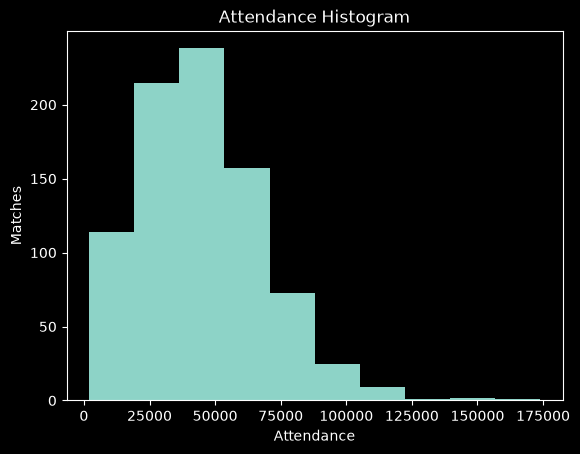

In [11]:
plt.hist(data["Attendance"])

plt.xlabel("Attendance")
plt.ylabel("Matches")
plt.title("Attendance Histogram")

plt.show()

In [12]:
data["Attendance"].describe()

count       835.000000
mean      44859.457485
std       23551.107893
min        2000.000000
25%       29800.000000
50%       41000.000000
75%       61009.000000
max      173850.000000
Name: Attendance, dtype: float64

In [13]:
attendance_median = data["Attendance"].median()
print(f"Attendance median: {attendance_median}")

Attendance median: 41000.0


In [14]:
data = data.fillna({"Attendance": attendance_median})
data.isna().sum()

Year                    0
Datetime                0
Stage                   0
Stadium                 0
City                    0
Home Team Name          0
Home Team Goals         0
Away Team Goals         0
Away Team Name          0
Win conditions          0
Attendance              0
Half-time Home Goals    0
Half-time Away Goals    0
Referee                 0
Assistant 1             0
Assistant 2             0
RoundID                 0
MatchID                 0
Home Team Initials      0
Away Team Initials      0
dtype: int64

## Remove unnecessary columns

In [15]:
data.columns

Index(['Year', 'Datetime', 'Stage', 'Stadium', 'City', 'Home Team Name',
       'Home Team Goals', 'Away Team Goals', 'Away Team Name',
       'Win conditions', 'Attendance', 'Half-time Home Goals',
       'Half-time Away Goals', 'Referee', 'Assistant 1', 'Assistant 2',
       'RoundID', 'MatchID', 'Home Team Initials', 'Away Team Initials'],
      dtype='str')

In [16]:
data = data.drop(columns=["Datetime", "Stadium", "City", "Referee", "Assistant 1", "Assistant 2"])
data.columns

Index(['Year', 'Stage', 'Home Team Name', 'Home Team Goals', 'Away Team Goals',
       'Away Team Name', 'Win conditions', 'Attendance',
       'Half-time Home Goals', 'Half-time Away Goals', 'RoundID', 'MatchID',
       'Home Team Initials', 'Away Team Initials'],
      dtype='str')

## Data types conversion

In [17]:
data.dtypes

Year                    float64
Stage                       str
Home Team Name              str
Home Team Goals         float64
Away Team Goals         float64
Away Team Name              str
Win conditions              str
Attendance              float64
Half-time Home Goals    float64
Half-time Away Goals    float64
RoundID                 float64
MatchID                 float64
Home Team Initials          str
Away Team Initials          str
dtype: object

In [18]:
convert = {
    "Year": int,
    "Home Team Goals": int,
    "Away Team Goals": int,
    "Attendance": int,
    "Half-time Home Goals": int,
    "Half-time Away Goals": int,
    "RoundID": int,
    "MatchID": int,
}

data = data.astype(convert)
data.dtypes

Year                    int64
Stage                     str
Home Team Name            str
Home Team Goals         int64
Away Team Goals         int64
Away Team Name            str
Win conditions            str
Attendance              int64
Half-time Home Goals    int64
Half-time Away Goals    int64
RoundID                 int64
MatchID                 int64
Home Team Initials        str
Away Team Initials        str
dtype: object

# 4. Export

In [19]:
data

,Year,Stage,Home Team Name,Home Team Goals,Away Team Goals,Away Team Name,Win conditions,Attendance,Half-time Home Goals,Half-time Away Goals,RoundID,MatchID,Home Team Initials,Away Team Initials
0,1930,Group 1,France,4,1,Mexico,,4444,3,0,201,1096,FRA,MEX
1,1930,Group 4,USA,3,0,Belgium,,18346,2,0,201,1090,USA,BEL
2,1930,Group 2,Yugoslavia,2,1,Brazil,,24059,2,0,201,1093,YUG,BRA
3,1930,Group 3,Romania,3,1,Peru,,2549,1,0,201,1098,ROU,PER
4,1930,Group 1,Argentina,1,0,France,,23409,0,0,201,1085,ARG,FRA
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
847,2014,Quarter-finals,Argentina,1,0,Belgium,,68551,1,0,255953,300186504,ARG,BEL
848,2014,Round of 16,Netherlands,2,1,Mexico,,58817,0,0,255951,300186508,NED,MEX
849,2014,Round of 16,Costa Rica,1,1,Greece,Costa Rica win on penalties (5 - 3),41242,0,0,255951,300186459,CRC,GRE
850,2014,Round of 16,Argentina,1,0,Switzerland,Argentina win after extra time,63255,0,0,255951,300186503,ARG,SUI


In [20]:
data.to_csv("../data/clean/matches-pre2018.csv", index=False)